In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import ExponentialRepresentation
from scipy.stats import binned_statistic_2d

from utils import plot_ratemaps, rectify, construct_exponential, batch_inference

torch.set_default_dtype(torch.float64)

In [2]:
sA = torch.load("sigma_A.pt", weights_only=True) # Must run fourier_approximation.ipynb first now!
sB = torch.load("sigma_B.pt", weights_only=True)

Gr = torch.load("Gr.pt", weights_only=True)
p0 = torch.load("p0.pt", weights_only=True) 

A, B, R = construct_exponential(sA, sB, Gr)

n_units = A.shape[0] # A.shape = B.shape, so
model = ExponentialRepresentation(A, B)

/home/m/Documents/phd/ESR/model.py:20: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A = torch.tensor(A, device=self.device, requires_grad=False)
/home/m/Documents/phd/ESR/model.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.B = torch.tensor(B, device=self.device, requires_grad=False)


In [3]:
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 10 
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)]

p_ = batch_inference(model, r_batch, p0)
r = np.concatenate(r_batch)

100%|██████████| 500/500 [00:05<00:00, 92.54it/s] 


In [4]:
r.shape, p_.shape

((25000, 2), (25000, 256))

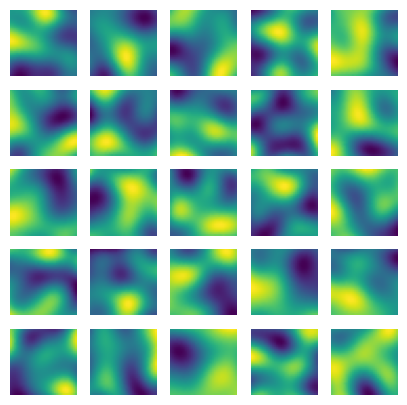

In [5]:
if rect:= False: # rectify or nay
    p = rectify(p_)
else:
    p = p_

ratemaps = plot_ratemaps(r[:,0], r[:,1], p, 5, figsize=(5,5), bins = 32)

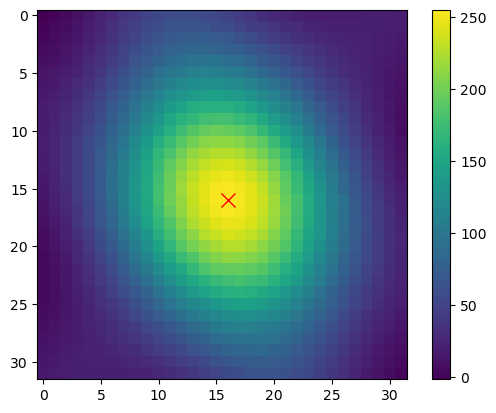

In [6]:
# plot correlation between vector at [a,a] and all other pop. vecs.
a = 16
prod = np.nansum(ratemaps[:,a, a, None,None]*ratemaps, axis = 0)
plt.imshow(prod.T)
plt.plot(a,a, "rx", markersize = 10)
plt.colorbar()